# Machine Learning for Methane Yield (CH₄) Prediction

## Notebook objective

This notebook develops and evaluates several machine-learning models to predict methane yield (CH₄) during CO₂ methanation from the operating conditions of a catalytic reactor using a nickel catalyst supported on zirconium dioxide (Ni/ZrO₂).

The main objective is to evaluate not only predictive accuracy, but also model **robustness and generalization ability** under different operating conditions.

## Research questions

### Q1 — Interpolation ability
Can the models accurately predict methane yield for new experiments within the studied operating domain?

### Q2 — Generalization to new operating regions
Can the models accurately predict methane yield in operating regions excluded from training?

### Q3 — Extrapolation ability
Can the models accurately predict methane yield beyond the temperature range used for training?

**RMSE** is the metric used to compare models across the three experiments.


In [15]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import root_mean_squared_error
from sklearn.model_selection import KFold
from sklearn.neural_network import MLPRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from xgboost import XGBRegressor

RANDOM_STATE = 42
sns.set_theme(style='whitegrid', context='notebook')

ROOT = Path.cwd().parent
DATA_PATH = ROOT / 'data' / 'processed' / 'co2_methanation_clean.csv'
RESULT_DIR = ROOT / 'reports' / 'baseline_ml'
RESULT_DIR.mkdir(parents=True, exist_ok=True)

## 1. Data loading and preparation

In [16]:
df = pd.read_csv(DATA_PATH)
df.head()

,test_id,temperature_C,CO2_pct,H2_pct,Ar_pct,GHSV_h-1,flowrate_NmL_min,CH4_yield_pct,H2_CO2_ratio
0,1,240.0,20.0,80.0,0.0,144000.0,599.0,11.09,4.000000
1,2,251.0,20.0,80.0,0.0,144000.0,599.0,17.27,4.000000
2,3,261.0,19.9,80.1,0.0,144000.0,599.0,25.56,4.025126
3,4,272.0,20.0,80.0,0.0,144000.0,599.0,34.50,4.000000
4,5,280.0,20.0,80.0,0.0,144000.0,599.0,43.86,4.000000


In [17]:
FEATURES = [
    'temperature_C',
    'GHSV_h-1',
    'H2_CO2_ratio',
    'Ar_pct',
]
TARGET = 'CH4_yield_pct'


X = df[FEATURES].copy()
y = df[TARGET].copy()

In [18]:
df[FEATURES + [TARGET]].describe().T

,count,mean,std,min,25%,50%,75%,max
temperature_C,215.0,248.106977,16.983023,219.000000,231.000000,250.00,260.000000,301.000000
GHSV_h-1,215.0,227226.976744,131555.708742,47800.000000,144000.000000,216000.00,216000.000000,720000.000000
H2_CO2_ratio,215.0,3.705452,1.043067,0.496503,3.957395,4.00,4.025126,6.042254
Ar_pct,215.0,11.088372,22.701324,0.000000,0.000000,0.00,0.000000,78.700000
CH4_yield_pct,215.0,11.447163,11.454941,0.150000,5.315000,8.17,12.935000,71.320000


## 2. Models and evaluation functions

Six models are compared: Linear Regression, Ridge, SVR, Random Forest, XGBoost, and a small neural network with one hidden layer. Standardization is included inside the pipelines of models that require it, preventing data leakage between training and testing.

In [19]:
MODELS = {
    'Linear Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('model', LinearRegression()),
    ]),
    'Ridge': Pipeline([
        ('scaler', StandardScaler()),
        ('model', Ridge(alpha=1.0)),
    ]),
    'SVR-RBF': Pipeline([
        ('scaler', StandardScaler()),
        ('model', SVR(C=10.0, epsilon=0.1, gamma='scale')),
    ]),
    'Random Forest': Pipeline([
        ('model', RandomForestRegressor(
            n_estimators=500, min_samples_leaf=2,
            random_state=RANDOM_STATE, n_jobs=-1,
        )),
    ]),
    'XGBoost': Pipeline([
        ('model', XGBRegressor(
            n_estimators=500, learning_rate=0.03, max_depth=3,
            subsample=0.9, colsample_bytree=0.9,
            objective='reg:squarederror', tree_method='hist',
            random_state=RANDOM_STATE, n_jobs=1, verbosity=0,
        )),
    ]),
    'Neural Network': Pipeline([
        ('scaler', StandardScaler()),
        ('model', MLPRegressor(
            hidden_layer_sizes=(32,), activation='relu', solver='adam',
            alpha=0.001, learning_rate_init=0.005, max_iter=1500,
            early_stopping=True, validation_fraction=0.15,
            n_iter_no_change=40, random_state=RANDOM_STATE,
        )),
    ]),
}

In [20]:
def evaluate_splits(models, X, y, splits, experiment):
    metric_rows = []
    prediction_rows = []

    for model_name, estimator in models.items():
        for split_id, (train_index, test_index) in enumerate(splits):
            fitted_model = clone(estimator)
            fitted_model.fit(X.iloc[train_index], y.iloc[train_index])
            predictions = fitted_model.predict(X.iloc[test_index])
            rmse = root_mean_squared_error(y.iloc[test_index], predictions)

            metric_rows.append({
                'experiment': experiment,
                'model': model_name,
                'split': split_id,
                'n_train': len(train_index),
                'n_test': len(test_index),
                'RMSE': float(rmse),
            })

            for row_index, observed, predicted in zip(
                test_index, y.iloc[test_index], predictions
            ):
                prediction_rows.append({
                    'experiment': experiment,
                    'model': model_name,
                    'split': split_id,
                    'row_index': int(row_index),
                    'test_id': int(df.iloc[row_index]['test_id']),
                    'observed': float(observed),
                    'predicted': float(predicted),
                    'residual': float(observed - predicted),
                })

    return pd.DataFrame(metric_rows), pd.DataFrame(prediction_rows)


def summarize_rmse(metrics):
    summary = metrics.groupby('model')['RMSE'].agg(['mean', 'std']).reset_index()
    summary = summary.rename(columns={'mean': 'RMSE_mean', 'std': 'RMSE_std'})
    return summary.sort_values('RMSE_mean').reset_index(drop=True)


## 3. Q1 — Interpolation ability

The data are randomly divided into five reproducible folds. Each observation is used once as test data.

In [21]:
kfold = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
interpolation_splits = list(kfold.split(X))
interpolation_metrics, interpolation_predictions = evaluate_splits(
    MODELS, X, y, interpolation_splits, experiment='interpolation'
)
interpolation_summary = summarize_rmse(interpolation_metrics)

interpolation_summary

,model,RMSE_mean,RMSE_std
0,Neural Network,1.753856,0.433995
1,XGBoost,2.157953,0.597825
2,SVR-RBF,2.583336,0.683580
3,Random Forest,3.120227,0.655983
4,Ridge,5.783681,0.631643
5,Linear Regression,5.784467,0.633270


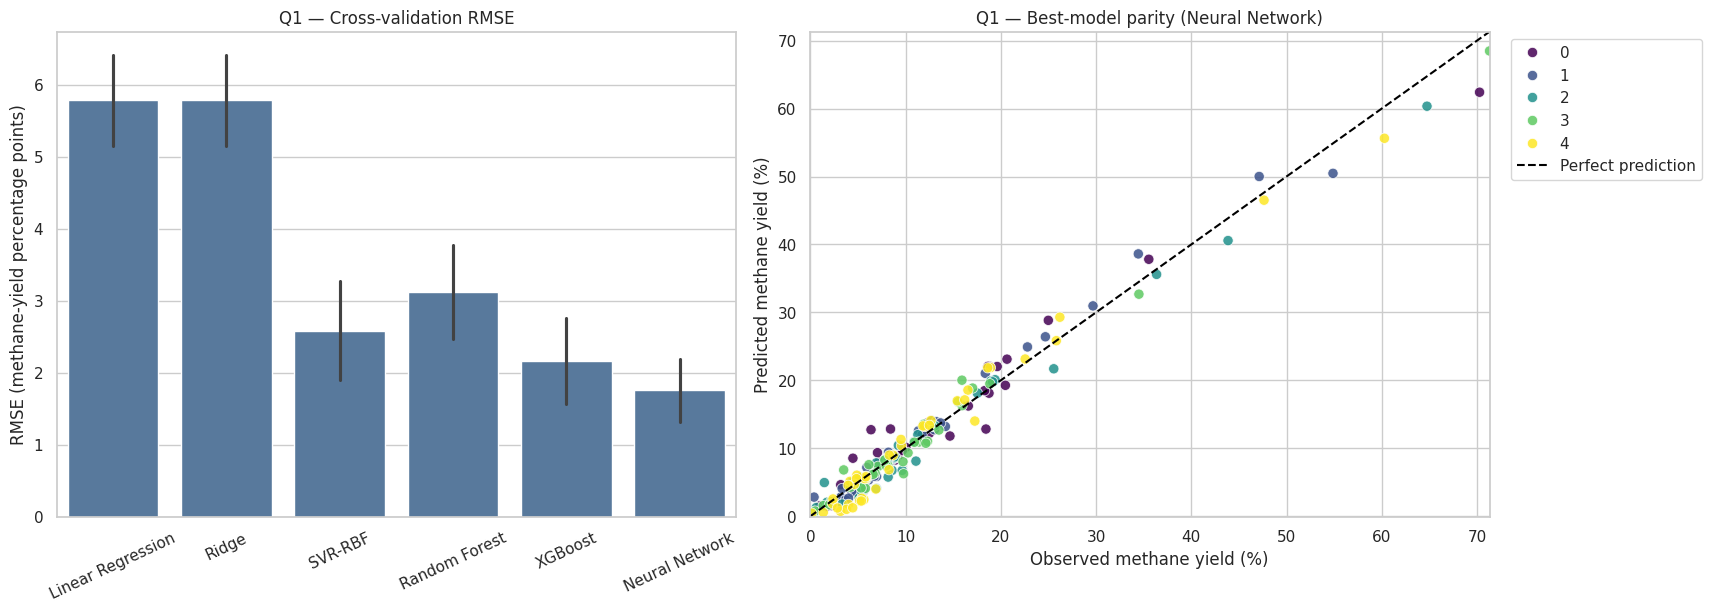

In [22]:
best_interpolation_model = interpolation_summary.iloc[0]['model']
best_interpolation_predictions = interpolation_predictions[
    interpolation_predictions['model'] == best_interpolation_model
]
parity_limits = [
    min(best_interpolation_predictions['observed'].min(), best_interpolation_predictions['predicted'].min()),
    max(best_interpolation_predictions['observed'].max(), best_interpolation_predictions['predicted'].max()),
]

fig, axes = plt.subplots(1, 2, figsize=(17, 6), constrained_layout=True)

sns.barplot(
    data=interpolation_metrics, x='model', y='RMSE', errorbar='sd',
    color='#4C78A8', ax=axes[0],
)
axes[0].set(
    title='Q1 — Cross-validation RMSE', xlabel='',
    ylabel='RMSE (methane-yield percentage points)',
)
axes[0].tick_params(axis='x', rotation=25)

sns.scatterplot(
    data=best_interpolation_predictions, x='observed', y='predicted', hue='split',
    palette='viridis', s=55, alpha=0.85, ax=axes[1],
)
axes[1].plot(
    parity_limits, parity_limits, '--', color='black',
    label='Perfect prediction',
)
axes[1].set(
    xlim=parity_limits, ylim=parity_limits,
    xlabel='Observed methane yield (%)',
    ylabel='Predicted methane yield (%)',
    title=f'Q1 — Best-model parity ({best_interpolation_model})',
)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')

fig.savefig(RESULT_DIR / 'interpolation_overview.png', dpi=180, bbox_inches='tight')
plt.show()

## 4. Q2 — Generalization to new operating regions

K-Means is to the four standardized input variables. The clusters represent five regions of the operating domain. Each region is then excluded from training in turn.

In [23]:
cluster_scaler = StandardScaler()
X_cluster_scaled = cluster_scaler.fit_transform(X)
kmeans = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE)
cluster_labels = kmeans.fit_predict(X_cluster_scaled)

clustered = df[['test_id', *FEATURES, TARGET]].copy()
clustered['cluster'] = cluster_labels
cluster_profile = clustered.groupby('cluster').agg(
    n=('test_id', 'size'),
    temperature_min=('temperature_C', 'min'),
    temperature_max=('temperature_C', 'max'),
    GHSV_min=('GHSV_h-1', 'min'),
    GHSV_max=('GHSV_h-1', 'max'),
    ratio_mean=('H2_CO2_ratio', 'mean'),
    Ar_mean=('Ar_pct', 'mean'),
    yield_mean=(TARGET, 'mean'),
)
cluster_profile

,n,temperature_min,temperature_max,GHSV_min,GHSV_max,ratio_mean,Ar_mean,yield_mean
cluster,,,,,,,,
0,20,230.0,262.0,214000.0,219000.0,4.048313,51.675000,13.144000
1,93,220.0,251.0,47800.0,360000.0,4.068583,0.527957,7.787097
2,31,219.0,270.0,360000.0,720000.0,4.001594,0.000000,3.965161
3,26,240.0,262.0,214000.0,221000.0,1.153007,49.503846,6.368077
4,45,260.0,301.0,108000.0,360000.0,4.073338,0.317778,26.346000


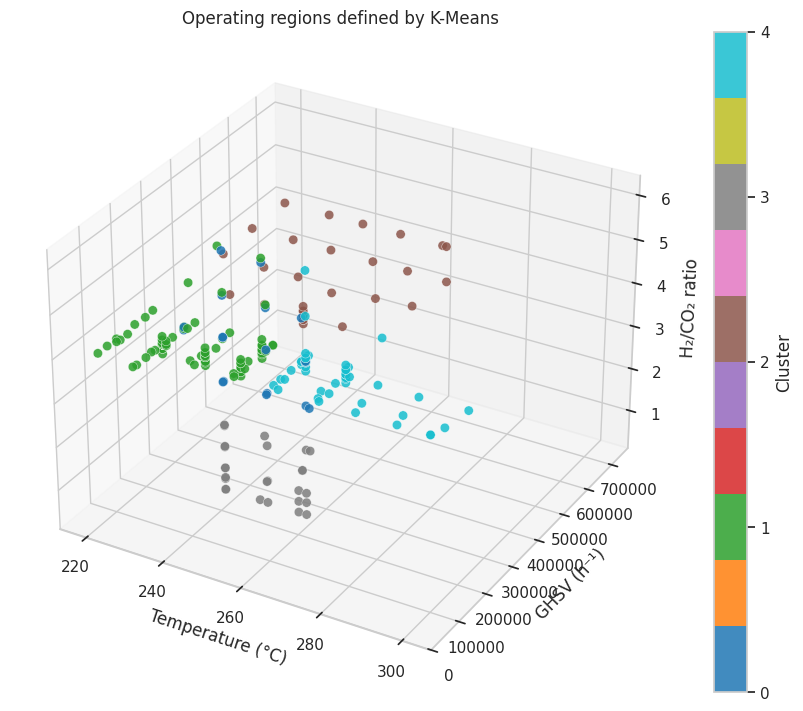

In [24]:
fig = plt.figure(figsize=(10, 7), constrained_layout=True)
ax = fig.add_subplot(111, projection='3d')
cluster_points = ax.scatter(
    clustered['temperature_C'], clustered['GHSV_h-1'],
    clustered['H2_CO2_ratio'], c=clustered['cluster'],
    cmap='tab10', s=45, alpha=0.85, edgecolor='white', linewidth=0.3,
)
ax.set(title='Operating regions defined by K-Means',
       xlabel='Temperature (°C)', ylabel='GHSV (h⁻¹)',
       zlabel='H₂/CO₂ ratio')
fig.colorbar(cluster_points, ax=ax, ticks=range(5), label='Cluster')
plt.show()

In [25]:
region_splits = [
    (np.flatnonzero(cluster_labels != cluster),
     np.flatnonzero(cluster_labels == cluster))
    for cluster in sorted(np.unique(cluster_labels))
]
region_metrics, region_predictions = evaluate_splits(
    MODELS, X, y, region_splits, experiment='leave_one_cluster_out'
)
region_summary = summarize_rmse(region_metrics)

region_summary

,model,RMSE_mean,RMSE_std
0,Neural Network,6.264348,3.685996
1,Random Forest,7.964838,6.807953
2,XGBoost,8.328447,6.525993
3,SVR-RBF,9.552592,7.517505
4,Ridge,11.998025,10.854561
5,Linear Regression,12.086528,10.982056


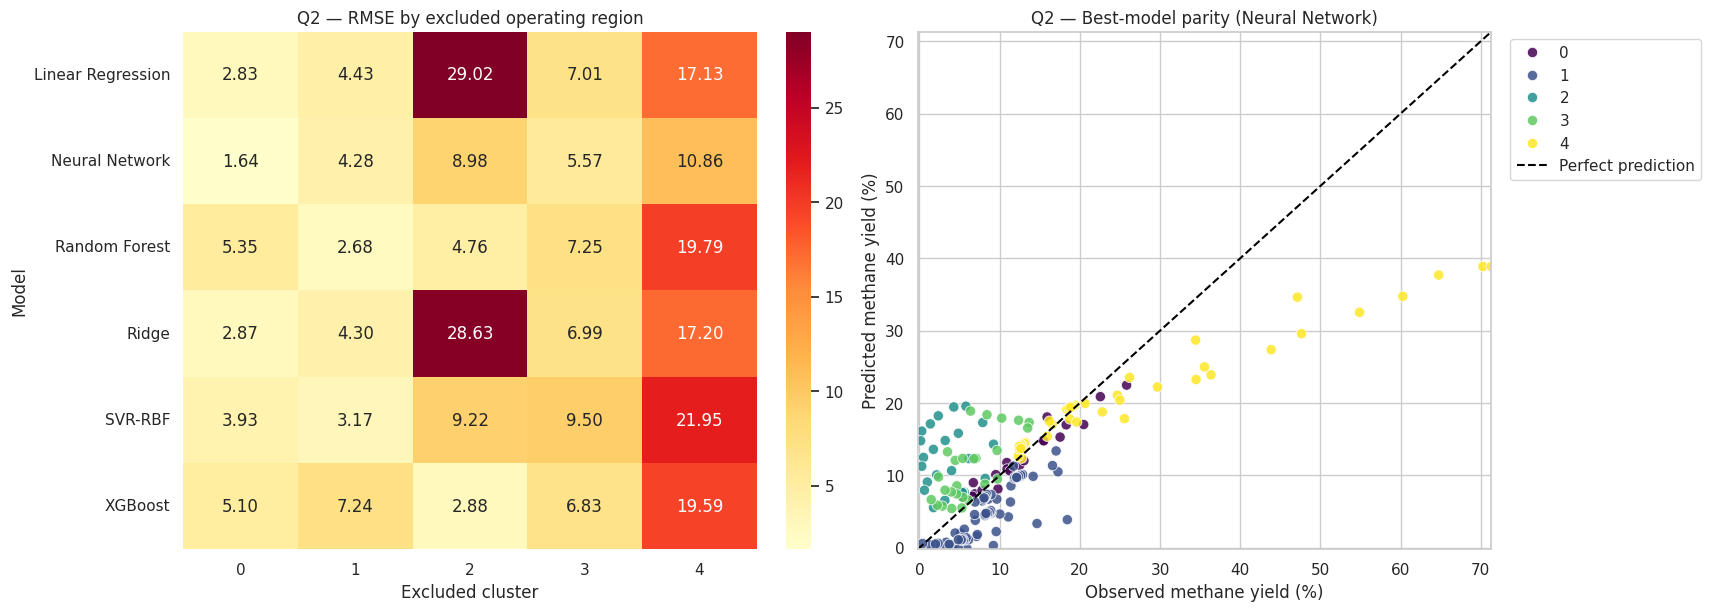

In [26]:
region_heatmap = region_metrics.pivot(index='model', columns='split', values='RMSE')
best_region_model = region_summary.iloc[0]['model']
best_region_predictions = region_predictions[
    region_predictions['model'] == best_region_model
]
region_limits = [
    min(best_region_predictions['observed'].min(), best_region_predictions['predicted'].min()),
    max(best_region_predictions['observed'].max(), best_region_predictions['predicted'].max()),
]

fig, axes = plt.subplots(1, 2, figsize=(17, 6), constrained_layout=True)
sns.heatmap(region_heatmap, annot=True, fmt='.2f', cmap='YlOrRd', ax=axes[0])
axes[0].set(title='Q2 — RMSE by excluded operating region',
            xlabel='Excluded cluster', ylabel='Model')
sns.scatterplot(
    data=best_region_predictions, x='observed', y='predicted', hue='split',
    palette='viridis', s=55, alpha=0.85, ax=axes[1],
)
axes[1].plot(region_limits, region_limits, '--', color='black',
             label='Perfect prediction')
axes[1].set(
    xlim=region_limits, ylim=region_limits,
    xlabel='Observed methane yield (%)', ylabel='Predicted methane yield (%)',
    title=f'Q2 — Best-model parity ({best_region_model})',
)
axes[1].legend(bbox_to_anchor=(1.02, 1), loc='upper left')
fig.savefig(RESULT_DIR / 'region_generalization.png', dpi=180, bbox_inches='tight')
plt.show()

## 5. Q3 — Extrapolation from 260 °C

Observations below 260 °C form the training set. The region from 260 °C upward remains completely unseen until the final evaluation.

In [27]:
extrapolation_train_index = np.flatnonzero(df['temperature_C'].to_numpy() < 260)
extrapolation_test_index = np.flatnonzero(df['temperature_C'].to_numpy() >= 260)
extrapolation_splits = [(extrapolation_train_index, extrapolation_test_index)]

print(f'Training: {len(extrapolation_train_index)} observations (<260 °C)')
print(f'Extrapolation test: {len(extrapolation_test_index)} observations (≥260 °C)')

extrapolation_metrics, extrapolation_predictions = evaluate_splits(
    MODELS, X, y, extrapolation_splits, experiment='temperature_extrapolation'
)
extrapolation_metrics = extrapolation_metrics.sort_values('RMSE').reset_index(drop=True)
extrapolation_metrics[['model', 'RMSE']]

Training: 151 observations (<260 °C)
Extrapolation test: 64 observations (≥260 °C)


,model,RMSE
0,Neural Network,10.416694
1,Linear Regression,15.069475
2,Ridge,15.115975
3,XGBoost,16.983650
4,Random Forest,17.806126
5,SVR-RBF,19.632800


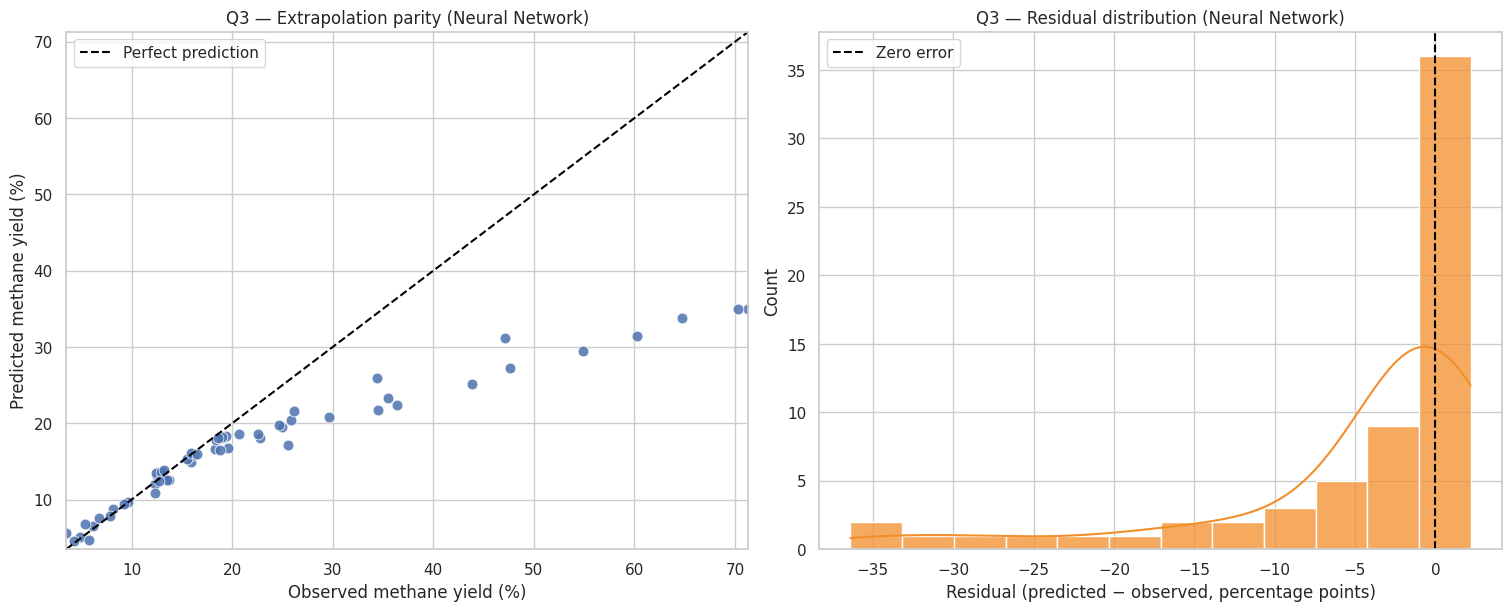

In [28]:
best_extrapolation_model = extrapolation_metrics.iloc[0]['model']
best_extrapolation_predictions = extrapolation_predictions[
    extrapolation_predictions['model'] == best_extrapolation_model
].copy()
best_extrapolation_predictions['temperature_C'] = df.iloc[
    best_extrapolation_predictions['row_index']
]['temperature_C'].to_numpy()
best_extrapolation_predictions = best_extrapolation_predictions.sort_values('temperature_C')
best_extrapolation_predictions['prediction_error'] = (
    best_extrapolation_predictions['predicted']
    - best_extrapolation_predictions['observed']
)
extrapolation_limits = [
    min(best_extrapolation_predictions['observed'].min(), best_extrapolation_predictions['predicted'].min()),
    max(best_extrapolation_predictions['observed'].max(), best_extrapolation_predictions['predicted'].max()),
]

fig, axes = plt.subplots(1, 2, figsize=(15, 6), constrained_layout=True)
sns.scatterplot(
    data=best_extrapolation_predictions, x='observed', y='predicted',
    s=60, alpha=0.85, ax=axes[0],
)
axes[0].plot(extrapolation_limits, extrapolation_limits, '--', color='black',
             label='Perfect prediction')
axes[0].set(
    xlim=extrapolation_limits, ylim=extrapolation_limits,
    xlabel='Observed methane yield (%)', ylabel='Predicted methane yield (%)',
    title=f'Q3 — Extrapolation parity ({best_extrapolation_model})',
)
axes[0].legend()
sns.histplot(
    data=best_extrapolation_predictions, x='prediction_error',
    bins=12, kde=True, color='#F28E2B', alpha=0.75, ax=axes[1],
)
axes[1].axvline(0, linestyle='--', color='black', label='Zero error')
axes[1].set(
    title=f'Q3 — Residual distribution ({best_extrapolation_model})',
    xlabel='Residual (predicted − observed, percentage points)',
    ylabel='Count',
)
axes[1].legend()
fig.savefig(RESULT_DIR / 'temperature_extrapolation.png', dpi=180, bbox_inches='tight')
plt.show()

## 6. Overall comparison

The final ranking places the three evaluations side by side. A robust model should interpolate accurately without collapsing when an operating region or the high-temperature range is absent from training.

In [29]:
comparison = (
    interpolation_summary[['model', 'RMSE_mean']].rename(
        columns={'RMSE_mean': 'interpolation_RMSE'}
    )
    .merge(
        region_summary[['model', 'RMSE_mean']].rename(
            columns={'RMSE_mean': 'region_RMSE'}
        ),
        on='model',
    )
    .merge(
        extrapolation_metrics[['model', 'RMSE']].rename(
            columns={'RMSE': 'extrapolation_RMSE'}
        ),
        on='model',
    )
)
for column in ['interpolation_RMSE', 'region_RMSE', 'extrapolation_RMSE']:
    comparison[f'{column}_rank'] = comparison[column].rank(method='average')
comparison['mean_rank'] = comparison[[
    'interpolation_RMSE_rank', 'region_RMSE_rank', 'extrapolation_RMSE_rank'
]].mean(axis=1)
comparison = comparison.sort_values('mean_rank').reset_index(drop=True)
comparison.to_csv(RESULT_DIR / 'model_comparison.csv', index=False)
comparison

,model,interpolation_RMSE,region_RMSE,extrapolation_RMSE,interpolation_RMSE_rank,region_RMSE_rank,extrapolation_RMSE_rank,mean_rank
0,Neural Network,1.753856,6.264348,10.416694,1.0,1.0,1.0,1.000000
1,XGBoost,2.157953,8.328447,16.983650,2.0,3.0,4.0,3.000000
2,Random Forest,3.120227,7.964838,17.806126,4.0,2.0,5.0,3.666667
3,SVR-RBF,2.583336,9.552592,19.632800,3.0,4.0,6.0,4.333333
4,Ridge,5.783681,11.998025,15.115975,5.0,5.0,3.0,4.333333
5,Linear Regression,5.784467,12.086528,15.069475,6.0,6.0,2.0,4.666667


In [31]:
best_robust_model = comparison.iloc[0]
print(f"Best overall baseline: {best_robust_model['model']}")
print(f"Interpolation RMSE: {best_robust_model['interpolation_RMSE']:.3f}")
print(f"Region RMSE: {best_robust_model['region_RMSE']:.3f}")
print(f"Extrapolation RMSE: {best_robust_model['extrapolation_RMSE']:.3f}")

Best overall baseline: Neural Network
Interpolation RMSE: 1.754
Region RMSE: 6.264
Extrapolation RMSE: 10.417


## Results interpretation

The Neural Network achieves the best overall performance because it can represent nonlinear relationships and interactions between temperature, GHSV, feed composition, and argon dilution. However, its performance depends strongly on how well the prediction region is represented in the training data.

### Interpolation

The Neural Network obtains an interpolation RMSE of **1.754 methane-yield percentage points**. Most observations in the parity plot are close to the perfect-prediction line. This strong result is partly explained by the random KFold strategy: experiments with similar operating conditions can appear in both the training and test folds. Consequently, the test observations remain relatively familiar to the model, and this result may be optimistic compared with prediction in a genuinely new operating regime.

**Answer to the interpolation question:** yes, the Neural Network can accurately predict new observations located within the operating domain represented by the training data.

### Generalization to new operating regions

The RMSE increases to **6.264 percentage points** during Leave-One-Cluster-Out validation. Performance varies considerably between clusters. Cluster 4 is the most difficult region because it contains high-temperature and high-methane-yield experiments and is sparsely represented in the dataset. When this cluster is excluded from training, the model has insufficient nearby observations from which to learn this regime and therefore systematically underpredicts its high yields.

**Answer to the regional-generalization question:** partially. The model generalizes well to some excluded regions, but it is not consistently reliable in rare operating regions that differ substantially from the training data.

### Temperature extrapolation

The extrapolation RMSE reaches **10.417 percentage points**. The model is trained only on temperatures below 260 °C, where low and moderate methane yields dominate. It therefore has little information about the rapid yield increase observed at higher temperatures. In the extrapolation parity plot, high-yield observations fall below the perfect-prediction line. The residual histogram also has a long negative tail because the residual is defined as predicted minus observed yield. Both plots demonstrate systematic underprediction of the high-temperature, high-yield experiments.

**Answer to the extrapolation question:** no, the model does not extrapolate reliably across the complete high-temperature region. It performs reasonably near the training boundary but increasingly underpredicts methane yield farther from the represented domain.

### Overall conclusion

The Neural Network is effective at learning nonlinear patterns when those patterns are represented in the training data. Its strong interpolation performance does not imply equally strong generalization or extrapolation. The deterioration observed for cluster 4 and for temperatures at or above 260 °C is mainly caused by distribution shift and the scarcity of high-temperature, high-yield experiments. Additional experiments in these sparse regions, or the introduction of physically informed constraints, would be required to improve reliability outside the densely sampled operating domain.